# Experiment-8: Abstractive Text Summarization with mT5 and mBART (XL-Sum, Urdu)

To implement and evaluate abstractive text summarization using two multilingual Transformer-based sequence-to-sequence models:
- **mT5** (Multilingual Text-to-Text Transfer Transformer)
- **mBART** (Multilingual Bidirectional and Auto-Regressive Transformers)

on one language of the **XL-Sum** dataset, and compare them with **ROUGE-1, ROUGE-2, ROUGE-L** and **mBERT score** (BERTScore computed with multilingual BERT).

**Language chosen: Urdu.**

| Model | Checkpoint | Base model | Fine-tuned on |
|---|---|---|---|
| mT5 | [`csebuetnlp/mT5_multilingual_XLSum`](https://huggingface.co/csebuetnlp/mT5_multilingual_XLSum) | `google/mt5-base` (580M) | XL-Sum, all 45 languages |
| mBART | [`eslamxm/MBart-finetuned-ur-xlsum`](https://huggingface.co/eslamxm/MBart-finetuned-ur-xlsum) | `facebook/mbart-large-50` (610M) | XL-Sum, Urdu |

Fine-tuning ~600M-parameter models needs a large GPU, so both models are used as published summarization checkpoints and evaluated on the same held-out XL-Sum Urdu **test** articles (never seen in training).

In [1]:
import gc
import re
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from datasets import load_dataset
from transformers import AutoTokenizer, AutoModelForSeq2SeqLM

device = "cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu"
print("Device:", device)

Device: mps


## 8.1. Loading the XL-Sum (Urdu) dataset

In [2]:
# only the Urdu test split (parquet export of csebuetnlp/xlsum)
URDU_TEST = "https://huggingface.co/datasets/csebuetnlp/xlsum/resolve/refs%2Fconvert%2Fparquet/urdu/test/0000.parquet"

xlsum_test = load_dataset("parquet", data_files={"test": URDU_TEST}, split="test")
xlsum_test

Dataset({
    features: ['id', 'url', 'title', 'summary', 'text'],
    num_rows: 8458
})

In [3]:
NUM_SAMPLES = 100          # articles evaluated per model (generation is slow on a laptop)

test_df = xlsum_test.shuffle(seed=42).select(range(NUM_SAMPLES)).to_pandas()[["title", "text", "summary"]]

print("Average article length (words):", round(test_df["text"].str.split().str.len().mean(), 1))
print("Average summary length (words):", round(test_df["summary"].str.split().str.len().mean(), 1))
test_df.head(3)

Average article length (words): 459.8
Average summary length (words): 33.0


,title,text,summary
0,’ایک پشتون کی برسی پر تقریب کو بھی خطرے کا باع...,پی ٹی ایم کی مقبولیت سے متعلق بحث کی تقریب کو ...,13 اپریل کو کراچی کی حبیب یونیورسٹی کے پروگرام...
1,تھائی لینڈ میں فوجی سربراہ وزیراعظم نامزد,جمعرات کو جنرل پرایوتھ کے انتخاب میں تھائی لین...,تھائی لینڈ میں جنتا یعنی حکمران عسکری گروہ کے ...
2,چین امریکی اہداف پر ’حملوں کی مشق‘ کر رہا ہے: ...,پینٹاگون کی رپورٹ کے مطابق اندازہ ہے کہ چین کا...,امریکی محکمہ دفاع پینٹاگون کی ایک نئی رپورٹ می...


In [4]:
WHITESPACE_HANDLER = lambda k: re.sub(r"\s+", " ", re.sub(r"\n+", " ", k.strip()))

articles = [WHITESPACE_HANDLER(t) for t in test_df["text"]]
references = test_df["summary"].tolist()

A shared generation routine so that both models are decoded with the same settings (beam search, 4 beams, no repeated bigrams).

In [5]:
def summarize(model, tokenizer, texts, batch_size=4, max_input_length=512, max_new_tokens=84, **gen_kwargs):
    model.eval()
    summaries = []
    for start in range(0, len(texts), batch_size):
        batch = texts[start:start + batch_size]
        inputs = tokenizer(batch, return_tensors="pt", padding=True,
                           truncation=True, max_length=max_input_length).to(device)
        with torch.no_grad():
            output_ids = model.generate(
                **inputs,
                max_new_tokens=max_new_tokens,
                num_beams=4,
                no_repeat_ngram_size=2,
                early_stopping=True,
                **gen_kwargs,
            )
        summaries += tokenizer.batch_decode(output_ids, skip_special_tokens=True)
    return [s.strip() for s in summaries]

## 8.2. Summarization with mT5

In [6]:
mt5_name = "csebuetnlp/mT5_multilingual_XLSum"

mt5_tokenizer = AutoTokenizer.from_pretrained(mt5_name)
mt5_model = AutoModelForSeq2SeqLM.from_pretrained(mt5_name).to(device)

print("mT5 parameters: %.0fM" % (sum(p.numel() for p in mt5_model.parameters()) / 1e6))

mT5 parameters: 582M


In [7]:
%%time
mt5_summaries = summarize(mt5_model, mt5_tokenizer, articles)

CPU times: user 58.9 s, sys: 32.4 s, total: 1min 31s
Wall time: 4min 40s


In [8]:
# free memory before loading the second model
del mt5_model
gc.collect()
if device == "mps":
    torch.mps.empty_cache()

## 8.3. Summarization with mBART
mBART-50 needs the source language code (`ur_PK`) on the encoder side and has to be forced to start the summary with the Urdu language token.

In [9]:
mbart_name = "eslamxm/MBart-finetuned-ur-xlsum"

mbart_tokenizer = AutoTokenizer.from_pretrained(mbart_name, src_lang="ur_PK", tgt_lang="ur_PK")
mbart_model = AutoModelForSeq2SeqLM.from_pretrained(mbart_name).to(device)

print("mBART parameters: %.0fM" % (sum(p.numel() for p in mbart_model.parameters()) / 1e6))

mBART parameters: 611M


In [10]:
%%time
mbart_summaries = summarize(
    mbart_model, mbart_tokenizer, articles,
    batch_size=2,           # mBART-large + 250k-token vocabulary: smaller batches to fit in memory
    forced_bos_token_id=mbart_tokenizer.convert_tokens_to_ids("ur_PK"),
)

CPU times: user 1min 42s, sys: 58.2 s, total: 2min 40s
Wall time: 7min 51s


In [11]:
del mbart_model
gc.collect()
if device == "mps":
    torch.mps.empty_cache()

results_df = pd.DataFrame({"reference": references, "mt5": mt5_summaries, "mbart": mbart_summaries})
results_df.to_csv("xlsum_urdu_predictions.csv", index=False)

## 8.4. Sample summaries

In [12]:
for i in range(3):
    print(f"--- Article {i + 1}: {test_df['title'].iloc[i]}")
    print("Reference:", references[i])
    print("mT5      :", mt5_summaries[i])
    print("mBART    :", mbart_summaries[i])
    print()

--- Article 1: ’ایک پشتون کی برسی پر تقریب کو بھی خطرے کا باعث سمجھا جا رہا ہے‘
Reference: 13 اپریل کو کراچی کی حبیب یونیورسٹی کے پروگرام ڈائریکٹر اور ماہر معاشیات، ڈاکٹر فہد علی اپنے لیکچر کی تیاری کر رہے تھے جب انھیں انتظامیہ نے ہنگامی میٹنگ کے لیے طلب کیا۔
mT5      : پاکستان کے صوبہ خیبر پختونخوا کے ضلع ڈیرہ اسماعیل خان میں حبیب یونیورسٹی میں گذشتہ روز پشتون تحفظ تحریک (پی ٹی ایم) کی مقبولیت سے متعلق بحث کی تقریب کو اچانک منسوخ کر دیا گیا ہے۔
mBART    : پاکستان کے صوبہ پنجاب کے ضلع ڈیرہ اسماعیل خان میں پشتون تحفظ تحریک (پی ٹی ایم) کی مقبولیت سے متعلق بحث کی تقریب کو اچانک منسوخ کر دیا گیا ہے۔

--- Article 2: تھائی لینڈ میں فوجی سربراہ وزیراعظم نامزد
Reference: تھائی لینڈ میں جنتا یعنی حکمران عسکری گروہ کے سربراہ پرایوتھ چان اوچا کو ملک کا نیا وزیراعظم نامزد کر دیا گیا ہے۔
mT5      : تھائی لینڈ کی نیشنل اسمبلی نے سابق فوجی سربراہ جنرل پرا یوتھ کو ملک کے نئے وزیرِ اعظم کا عہدہ سنبھال لیا ہے۔
mBART    : تھائی لینڈ میں جنتا کے قانون سازوں نے ملک کے سب سے طاقتور فوجی جنرل کا انتخاب کر لی

## 8.5. Evaluation – ROUGE-1, ROUGE-2, ROUGE-L

The default `rouge_score` tokenizer keeps only `[a-z0-9]` characters, which would delete every Urdu word and give a score of 0. A Unicode-aware tokenizer (split on whitespace after removing punctuation) is passed in instead – the same idea as the multilingual ROUGE used by the XL-Sum authors.

In [13]:
from rouge_score import rouge_scorer


class MultilingualTokenizer:
    def tokenize(self, text):
        text = re.sub(r"[^\w\s]", " ", text.lower())     # \w is Unicode-aware: keeps Urdu letters
        return text.split()


scorer = rouge_scorer.RougeScorer(["rouge1", "rouge2", "rougeL"], tokenizer=MultilingualTokenizer())


def rouge_scores(predictions, references):
    scores = [scorer.score(ref, pred) for pred, ref in zip(predictions, references)]
    return {key: 100 * np.mean([s[key].fmeasure for s in scores]) for key in ["rouge1", "rouge2", "rougeL"]}


mt5_rouge = rouge_scores(mt5_summaries, references)
mbart_rouge = rouge_scores(mbart_summaries, references)

pd.DataFrame([mt5_rouge, mbart_rouge], index=["mT5", "mBART"]).round(2)

,rouge1,rouge2,rougeL
mT5,40.70,19.32,33.72
mBART,41.75,19.12,34.21


## 8.6. Evaluation – mBERT score
BERTScore matches candidate and reference tokens by the cosine similarity of their contextual embeddings; `bert-base-multilingual-cased` (mBERT) provides the embeddings for Urdu.

In [14]:
from bert_score import score as bert_score

def mbert_score(predictions, references):
    P, R, F1 = bert_score(predictions, references, model_type="bert-base-multilingual-cased",
                          device=device, batch_size=16, verbose=False)
    return {"mBERT P": 100 * P.mean().item(), "mBERT R": 100 * R.mean().item(), "mBERT F1": 100 * F1.mean().item()}


mt5_bert = mbert_score(mt5_summaries, references)
mbart_bert = mbert_score(mbart_summaries, references)

pd.DataFrame([mt5_bert, mbart_bert], index=["mT5", "mBART"]).round(2)

,mBERT P,mBERT R,mBERT F1
mT5,78.81,75.96,77.32
mBART,78.35,76.59,77.42


## 8.7. Comparative analysis

In [15]:
comparison = pd.DataFrame(
    [{**mt5_rouge, **mt5_bert}, {**mbart_rouge, **mbart_bert}],
    index=["mT5", "mBART"],
).rename(columns={"rouge1": "ROUGE-1", "rouge2": "ROUGE-2", "rougeL": "ROUGE-L"})

comparison["Avg summary length (words)"] = [
    np.mean([len(s.split()) for s in mt5_summaries]),
    np.mean([len(s.split()) for s in mbart_summaries]),
]
comparison.round(2)

,ROUGE-1,ROUGE-2,ROUGE-L,mBERT P,mBERT R,mBERT F1,Avg summary length (words)
mT5,40.70,19.32,33.72,78.81,75.96,77.32,23.98
mBART,41.75,19.12,34.21,78.35,76.59,77.42,27.44


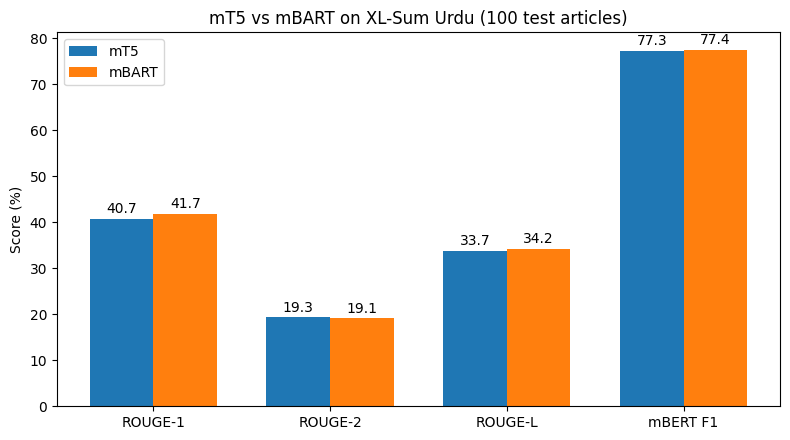

In [16]:
metrics = ["ROUGE-1", "ROUGE-2", "ROUGE-L", "mBERT F1"]
x = np.arange(len(metrics))
width = 0.36

fig, ax = plt.subplots(figsize=(8, 4.5))
bars1 = ax.bar(x - width / 2, comparison.loc["mT5", metrics], width, label="mT5")
bars2 = ax.bar(x + width / 2, comparison.loc["mBART", metrics], width, label="mBART")
ax.bar_label(bars1, fmt="%.1f", padding=2)
ax.bar_label(bars2, fmt="%.1f", padding=2)
ax.set_xticks(x, metrics)
ax.set_ylabel("Score (%)")
ax.set_title(f"mT5 vs mBART on XL-Sum Urdu ({NUM_SAMPLES} test articles)")
ax.legend()
plt.tight_layout()
plt.show()

In [17]:
# per-article ROUGE-L: how often does each model win?
mt5_rl = np.array([scorer.score(r, p)["rougeL"].fmeasure for p, r in zip(mt5_summaries, references)])
mbart_rl = np.array([scorer.score(r, p)["rougeL"].fmeasure for p, r in zip(mbart_summaries, references)])

pd.Series({
    "mT5 better": int((mt5_rl > mbart_rl).sum()),
    "mBART better": int((mbart_rl > mt5_rl).sum()),
    "Tie": int((mt5_rl == mbart_rl).sum()),
}, name="Articles (by ROUGE-L)")

mT5 better      51
mBART better    49
Tie              0
Name: Articles (by ROUGE-L), dtype: int64

In [18]:
best = comparison[metrics].idxmax()
print("Best model per metric:")
for metric, model_name in best.items():
    print(f"  {metric:9}: {model_name}  ({comparison.loc['mT5', metric]:.2f} vs {comparison.loc['mBART', metric]:.2f})")

Best model per metric:
  ROUGE-1  : mBART  (40.70 vs 41.75)
  ROUGE-2  : mT5  (19.32 vs 19.12)
  ROUGE-L  : mBART  (33.72 vs 34.21)
  mBERT F1 : mBART  (77.32 vs 77.42)


### Observations

| | ROUGE-1 | ROUGE-2 | ROUGE-L | mBERT F1 | Avg length (words) |
|---|---|---|---|---|---|
| mT5 | 40.70 | **19.32** | 33.72 | 77.32 | 24.0 |
| mBART | **41.75** | 19.12 | **34.21** | **77.42** | 27.4 |

- **The two models are almost tied.** mBART is ahead on ROUGE-1, ROUGE-L and mBERT F1, mT5 on ROUGE-2, and every gap is about 1 point or less. Per article, mT5 wins 51 and mBART 49 by ROUGE-L, so on 100 articles neither model is clearly better.
- **mBART's small edge** fits its training: it was fine-tuned on Urdu only, while mT5 shares its capacity across 45 XL-Sum languages. mBART also writes slightly longer summaries (27 vs 24 words, references average 33), which helps the recall side of ROUGE-1/ROUGE-L and mBERT R.
- **ROUGE vs mBERT score:** ROUGE counts exact word overlap, so paraphrases score low (ROUGE-2 is only about 19). mBERT score compares contextual embeddings and credits paraphrases, so its values are much higher (about 77) and the models end up even closer together.
- **Errors are mostly hallucinated details.** In article 1 both models place a Karachi university event in Dera Ismail Khan, and mBART even names the wrong province (Punjab). Both summaries are fluent but not faithful to the article, a known weakness of abstractive summarization that ROUGE does not penalise much.
- **Language tokens matter for mBART-50.** The source language (`ur_PK`) and `forced_bos_token_id` must be set, otherwise it can generate in the wrong language. mT5 needs no language token.